In [1]:
import urllib.parse
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
import numpy as np
from pathlib import Path
import json

In [2]:
# Create the temporary directory for outputs
output_dir = Path("tmp_wfs")
output_dir.mkdir(parents=True, exist_ok=True)

## Coordinates

In [3]:
minx, maxx = 6.6936, 6.7053
miny, maxy = 48.4199, 48.4316

center_lat = 48.4235
center_lon = 6.7001

side_length_meters = 1000

# Conversion factors
meters_per_deg_lat = 111000.0
meters_per_deg_lon = 111000.0 * np.cos(np.radians(center_lat))

# Calculate half-spans in degrees
half_lat_deg = (side_length_meters / 2) / meters_per_deg_lat
half_lon_deg = (side_length_meters / 2) / meters_per_deg_lon

# Define the corrected square bounding box
minx = center_lon - half_lon_deg
maxx = center_lon + half_lon_deg
miny = center_lat - half_lat_deg
maxy = center_lat + half_lat_deg

bounding_box = box(minx, miny, maxx, maxy)

## Fetch data from IGN Géoplateforme WFS

In [4]:
wfs_url = "https://data.geopf.fr/wfs/ows"
params = {
    "service": "WFS",
    "version": "2.0.0",
    "request": "GetFeature",
    "typeNames": "LANDCOVER.FORESTINVENTORY.V2:formation_vegetale",
    "outputFormat": "application/json",
    "srsName": "EPSG:4326",
    "bbox": f"{minx},{miny},{maxx},{maxy},EPSG:4326"
}

request_url = f"{wfs_url}?{urllib.parse.urlencode(params)}"

print("Fetching exact BD Forêt v2 attributes from IGN...")
gdf = gpd.read_file(request_url)

if not gdf.empty:
    
    print("Available database columns:")
    print(gdf.columns.tolist())
    
    # Identify the primary column containing the exact description
    label_column = "tfv" if "tfv" in gdf.columns else ("code_tfv" if "code_tfv" in gdf.columns else gdf.columns[0])
    
    # Save the downloaded GeoDataFrame locally inside "tmp_wfs"
    output_gpkg = output_dir / "bd_foret_square.gpkg"
    gdf.to_file(output_gpkg, driver="GPKG")
    print(f"\nSaved GeoDataFrame to {output_gpkg}")
    
else:
    print("No features returned for this bounding box.")    

Fetching exact BD Forêt v2 attributes from IGN...
Available database columns:
['id', 'code_tfv', 'tfv', 'tfv_g11', 'essence', 'geometry']

Saved GeoDataFrame to tmp_wfs/bd_foret_square.gpkg


## Display

Saved plot image to tmp_wfs/bd_foret_plot.png


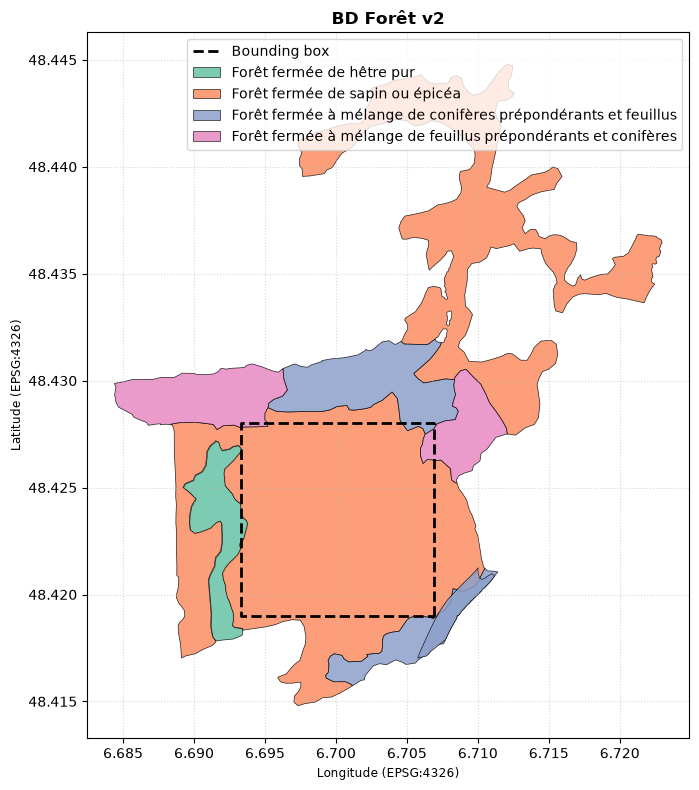

In [5]:
if not gdf.empty:

    fig, ax = plt.subplots(figsize=(11, 8))

    bx, by = bounding_box.exterior.xy
    ax.plot(bx, by, color="black", linestyle="--", linewidth=2, label="Bounding box")

    # Plot colored polygons (tree types)
    gdf.plot(
        column=label_column,
        ax=ax,
        cmap="Set2",
        legend=True,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.85,
        legend_kwds={"loc": "upper right"}
    )
    
    ax.set_title("BD Forêt v2", fontsize=12, fontweight="bold")
    ax.set_xlabel("Longitude (EPSG:4326)")
    ax.set_ylabel("Latitude (EPSG:4326)")
    plt.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    
    output_plot = output_dir / "bd_foret_plot.png"
    plt.savefig(output_plot, dpi=300)
    print(f"Saved plot image to {output_plot}")
    
    plt.show()


## Construct the corresponding GeoJSON Feature dictionary

In [6]:
geojson_feature = {
    "type": "Feature",
    "properties": {},
    "geometry": {
        "type": "Polygon",
        "coordinates": [
            [
                [maxx, miny],
                [minx, miny],
                [minx, maxy],
                [maxx, maxy],
                [maxx, miny],
            ]
        ]
    }
}

print(json.dumps(geojson_feature, indent=2))

{
  "type": "Feature",
  "properties": {},
  "geometry": {
    "type": "Polygon",
    "coordinates": [
      [
        [
          6.706887782567258,
          48.418995495495494
        ],
        [
          6.693312217432742,
          48.418995495495494
        ],
        [
          6.693312217432742,
          48.4280045045045
        ],
        [
          6.706887782567258,
          48.4280045045045
        ],
        [
          6.706887782567258,
          48.418995495495494
        ]
      ]
    ]
  }
}
